# The dictionary ceiling of a composition-based password meter

Every number in the paper comes from this notebook. Run the cells in order
from the top. It takes roughly eight minutes and needs no dataset download:
the breach corpus and the six ranked dictionaries ship with the `zxcvbn`
package installed in the first cell.

**What the notebook establishes, in order:**

| part | question |
|---|---|
| A | which passwords are we judging the meter on, and how do the populations overlap? |
| B | what does the reference estimator actually say about each population? |
| C | how often does the meter clear a known-breached password? |
| D | which of the meter's five named checks is responsible? |
| E | four configurations of the meter, plus a plain blocklist screen as baseline |
| F--I | the same measurement under each, with intervals, costs, and the residual |
| J--L | a null model, sensitivity of the constants, band-level agreement |
| M | the base rate the residual finding has to be read against |
| N | a 2x2 separating the entropy bonus from the penalties |
| O | a fourth repair that acts on the entropy term instead of the word list |
| P | the trade-off frontier: every configuration on both axes at once |
| Q | paired significance tests (exact McNemar) for every pair |
| R | how strong the "acceptable" passwords actually are |
| S | sensitivity of the whole-string penalty |
| T | what the blocklist baseline does and does not establish |
| U--V | the dictionary's corpus as a free parameter, and what varying it decides |

Fixed seed 42 throughout; the output is identical on repeated runs and on
different library versions.


## A. environment

In [1]:
# The reference estimator ships the ranked corpora this notebook uses as
# both the breach list and the dictionary source, so nothing else has to
# be downloaded and the notebook runs offline once this cell has run.
import importlib, subprocess, sys
try:
    importlib.import_module('zxcvbn')
    print("zxcvbn already available")
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'zxcvbn'],
                   check=True)
    print("zxcvbn installed")


zxcvbn installed


## B. setup

In [2]:
import sys, math, string, random, collections, platform
import numpy as np
import pandas as pd
from zxcvbn import zxcvbn
from zxcvbn import matching
from scipy.stats import spearmanr, fisher_exact

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)

CORPORA = ['passwords', 'english_wikipedia', 'female_names',
           'male_names', 'surnames', 'us_tv_and_film']
REF = matching.RANKED_DICTIONARIES
print("reference corpora shipped with the baseline estimator")
for k in ['passwords', 'english_wikipedia', 'surnames', 'us_tv_and_film',
          'female_names', 'male_names']:
    print("  %-20s %6d entries" % (k, len(REF[k])))
BREACH = list(REF['passwords'].keys())
assert len(BREACH) == 30000, len(BREACH)
print("\nthe breach list is the evaluation population: %d real passwords" % len(BREACH))


def wilson(k, n, z=1.96):
    """Wilson score interval for a binomial proportion, in percent."""
    if n == 0:
        return (float('nan'), float('nan'))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (round(100 * max(0.0, c - h), 2), round(100 * min(1.0, c + h), 2))


print("\n  Every rate in this notebook is reported with a 95%% Wilson interval.")
print("  wilson(104, 229) = %s   (a check of the function on a known row)"
      % (wilson(104, 229),))


reference corpora shipped with the baseline estimator
  passwords             30000 entries
  english_wikipedia     30000 entries
  surnames              10000 entries
  us_tv_and_film        19160 entries
  female_names           3712 entries
  male_names              983 entries

the breach list is the evaluation population: 30000 real passwords

  Every rate in this notebook is reported with a 95%% Wilson interval.
  wilson(104, 229) = (39.09, 51.89)   (a check of the function on a known row)


## C. the meter under test, reproduced exactly

In [3]:
# A composition-based meter written for a Master's dissertation project
# (MIT licence). It is fully transparent: a 0-100 additive score from
# length, character classes and an entropy term, minus penalties for
# structures the tool can name. The word list and pattern list below are
# the ones the published tool ships.

MIN_LENGTH, RECOMMENDED_LENGTH = 8, 15
SCORE = {"LENGTH_15": 30, "LENGTH_12": 20, "LENGTH_8": 10,
         "UPPERCASE": 10, "LOWERCASE": 10, "DIGIT": 10, "SYMBOL": 10,
         "ENTROPY_HIGH": 30, "ENTROPY_MEDIUM": 20, "ENTROPY_LOW": 10}
PENALTY = {"DICTIONARY": 20, "KEYBOARD": 15, "SEQUENTIAL": 15,
           "REPEATED": 10, "PATTERN": 10}
BANDS = [(20, "Very Weak"), (40, "Weak"), (60, "Moderate"), (80, "Strong")]

WORDS_PUBLISHED = set("""password admin administrator welcome welcome123 login guest
root user test computer internet security network database python project software
technology student teacher engineer developer science artificial intelligence machine
learning football cricket pakistan islamabad lahore karachi quetta peshawar github
google microsoft openai laptop mobile system data cloud office company family hello
secret dragon monkey sunshine master love qwerty abc letmein iloveyou princess superman
batman trustno1 whatever changeme starwars summer winter january december manager
default""".split())
PATTERNS_PUBLISHED = ["qwerty", "asdf", "zxcv", "qazwsx", "wasd",
                      "12345", "123456", "987654", "1234", "password", "admin"]
print("published word list   : %d entries" % len(WORDS_PUBLISHED))
print("published pattern list: %d entries" % len(PATTERNS_PUBLISHED))


def find_words(pw, words):
    """Every dictionary entry that appears inside the password. Looking up
    the password's own substrings is equivalent to scanning the whole list
    and is what makes a list of this size usable."""
    low = pw.lower()
    n = len(low)
    hits = set()
    for i in range(n):
        for j in range(i + 3, n + 1):
            s = low[i:j]
            if s in words:
                hits.add(s)
    return sorted(hits)


def find_patterns(pw, patterns):
    low = pw.lower()
    return [p for p in patterns if p in low]


def find_sequences(pw):
    out = []
    for i in range(len(pw) - 2):
        t = pw[i:i + 3]
        if t.isdigit():
            if ord(t[1]) == ord(t[0]) + 1 and ord(t[2]) == ord(t[1]) + 1:
                out.append(t)
            elif ord(t[1]) == ord(t[0]) - 1 and ord(t[2]) == ord(t[1]) - 1:
                out.append(t)
    return sorted(set(out))


def has_repeats(pw):
    return any(n >= 3 for n in collections.Counter(pw).values())


def has_alternating(pw):
    if len(pw) < 6:
        return False
    m = sum(1 for a, b in zip(pw, pw[1:])
            if (a.isalpha() and b.isdigit()) or (a.isdigit() and b.isalpha()))
    return m >= len(pw) // 2


def entropy_bits(pw):
    pool = 0
    if any(c.islower() for c in pw): pool += 26
    if any(c.isupper() for c in pw): pool += 26
    if any(c.isdigit() for c in pw): pool += 10
    if any(c in string.punctuation for c in pw): pool += len(string.punctuation)
    return (round(len(pw) * math.log2(pool), 2), pool) if pool else (0.0, 0)


# The entropy term carries its own deductions, which are NOT the same as the
# score penalties above: they are in bits, the dictionary deduction scales
# with the number of matches, and three of them depend on length alone.
ENT_LEN = {"SHORT": 35, "MEDIUM": 20, "LONG": 10}
ENT_PEN = {"DICT_EACH": 20, "DICT_CAP": 40, "PATTERN": 15,
           "SEQUENTIAL": 15, "REPEATED": 10, "ALTERNATING": 15}


def effective_entropy(pw, words, patterns):
    e = entropy_bits(pw)[0]
    if   len(pw) < MIN_LENGTH:         e -= ENT_LEN["SHORT"]
    elif len(pw) < 12:                 e -= ENT_LEN["MEDIUM"]
    elif len(pw) < RECOMMENDED_LENGTH: e -= ENT_LEN["LONG"]
    w = find_words(pw, words)
    if w: e -= min(len(w) * ENT_PEN["DICT_EACH"], ENT_PEN["DICT_CAP"])
    if patterns is not None and find_patterns(pw, patterns): e -= ENT_PEN["PATTERN"]
    if find_sequences(pw):  e -= ENT_PEN["SEQUENTIAL"]
    if has_repeats(pw):     e -= ENT_PEN["REPEATED"]
    if has_alternating(pw): e -= ENT_PEN["ALTERNATING"]
    return max(0.0, round(e, 2))


print("\n  the entropy term's own deductions, in bits (these differ from the")
print("  score penalties and are stated separately in the paper):")
print("    length  short/medium/long  -%d / -%d / -%d"
      % (ENT_LEN["SHORT"], ENT_LEN["MEDIUM"], ENT_LEN["LONG"]))
print("    dictionary  -%d per match, capped at -%d"
      % (ENT_PEN["DICT_EACH"], ENT_PEN["DICT_CAP"]))
print("    pattern -%d  sequence -%d  repeat -%d  alternating -%d"
      % (ENT_PEN["PATTERN"], ENT_PEN["SEQUENTIAL"],
         ENT_PEN["REPEATED"], ENT_PEN["ALTERNATING"]))


def score_password(pw, words=WORDS_PUBLISHED, patterns=PATTERNS_PUBLISHED,
                   walk_detector=None):
    """Returns the 0-100 score and the named weaknesses. `words`,
    `patterns` and `walk_detector` are the only things the repair changes."""
    s, why = 0, []
    n = len(pw)
    if   n >= RECOMMENDED_LENGTH: s += SCORE["LENGTH_15"]
    elif n >= 12:                 s += SCORE["LENGTH_12"]
    elif n >= MIN_LENGTH:         s += SCORE["LENGTH_8"]
    for key, test in [("UPPERCASE", str.isupper), ("LOWERCASE", str.islower),
                      ("DIGIT", str.isdigit)]:
        if any(test(c) for c in pw): s += SCORE[key]
    if any(not c.isalnum() for c in pw): s += SCORE["SYMBOL"]

    eff = effective_entropy(pw, words, patterns)
    if   eff >= 60: s += SCORE["ENTROPY_HIGH"]
    elif eff >= 40: s += SCORE["ENTROPY_MEDIUM"]
    elif eff >= 25: s += SCORE["ENTROPY_LOW"]

    if find_words(pw, words):
        s -= PENALTY["DICTIONARY"]; why.append("dictionary word")
    kb = find_patterns(pw, patterns) if patterns is not None else []
    if walk_detector is not None and walk_detector(pw):
        kb = kb + ["keyboard walk"]
    if kb:
        s -= PENALTY["KEYBOARD"]; why.append("keyboard pattern")
    if find_sequences(pw):
        s -= PENALTY["SEQUENTIAL"]; why.append("numeric sequence")
    if has_repeats(pw):
        s -= PENALTY["REPEATED"]; why.append("repeated characters")
    if has_alternating(pw):
        s -= PENALTY["PATTERN"]; why.append("alternating pattern")
    return max(0, min(s, 100)), why


def band(score):
    for cut, name in BANDS:
        if score <= cut: return name
    return "Excellent"


print("\n  %d band cut-offs (%s) produce %d bands"
      % (len(BANDS), ", ".join(str(c) for c, _ in BANDS), len(BANDS) + 1))

# the two examples the paper opens with
for demo in ["1qa2ws3ed4rf5tg", "correct-horse-battery-staple"]:
    sc, w = score_password(demo)
    print("  %-30s score %3d  band %-10s zxcvbn %d"
          % (demo, sc, band(sc), zxcvbn(demo)['score']))


published word list   : 72 entries
published pattern list: 11 entries

  the entropy term's own deductions, in bits (these differ from the
  score penalties and are stated separately in the paper):
    length  short/medium/long  -35 / -20 / -10
    dictionary  -20 per match, capped at -40
    pattern -15  sequence -15  repeat -10  alternating -15

  4 band cut-offs (20, 40, 60, 80) produce 5 bands
  1qa2ws3ed4rf5tg                score  70  band Strong     zxcvbn 1
  correct-horse-battery-staple   score  70  band Strong     zxcvbn 4


## D. the evaluation populations

In [4]:
print()
print("=" * 70)
print("  A. EVALUATION POPULATIONS")
print("=" * 70)

N_SAMPLE = 4000
rng = random.Random(SEED)

POP = {}
POP['breached (all lengths)'] = rng.sample(BREACH, N_SAMPLE)

# the part of the corpus a composition policy would admit, by length.
# Where the pool is smaller than N_SAMPLE this is a census, not a sample.
CENSUS = {}
for lo in (8, 10, 12):
    sub = [p for p in BREACH if len(p) >= lo]
    key = 'breached (%d+ chars)' % lo
    CENSUS[key] = len(sub) <= N_SAMPLE
    POP[key] = rng.sample(sub, min(N_SAMPLE, len(sub))) if sub else []

# what users produce under a composition policy: word, capital, year, symbol
wiki = [w for w in REF['english_wikipedia'] if 5 <= len(w) <= 9]
mut = []
for w in rng.sample(wiki, 2000):
    mut.append(w.capitalize() + str(rng.randint(1970, 2025)) + rng.choice('!@#$%'))
POP['policy-compliant mutations'] = mut

# passwords with no structure at all
ALPHA = string.ascii_letters + string.digits + "!@#$%^&*"
POP['random 16-character'] = ["".join(rng.choice(ALPHA) for _ in range(16))
                              for _ in range(2000)]

for k, v in POP.items():
    L = [len(p) for p in v]
    print("  %-28s n=%5d   mean length %.1f   %s"
          % (k, len(v), sum(L) / len(L),
             "census of the pool" if CENSUS.get(k) else "sample"))

ROWS = sum(len(v) for v in POP.values())
DISTINCT = len(set().union(*[set(v) for v in POP.values()]))
print("\n  rows across all six populations : %d" % ROWS)
print("  distinct password strings       : %d" % DISTINCT)
print("\n  How the breached populations relate to one another. Only the two")
print("  censuses are nested; the two 4,000-row draws are separate samples")
print("  from different pools, so they are NOT supersets of the censuses.")
BK = ['breached (all lengths)', 'breached (8+ chars)',
      'breached (10+ chars)', 'breached (12+ chars)']
for i in range(len(BK)):
    for j in range(len(BK)):
        if i >= j:
            continue
        a, b = set(POP[BK[j]]), set(POP[BK[i]])
        print("    %-22s subset of %-22s %-5s  (shared %d of %d)"
              % (BK[j].replace('breached ', ''), BK[i].replace('breached ', ''),
                 a <= b, len(a & b), len(a)))
print("  Tables that pool the populations therefore count rows, and the")
print("  overlap between them is an ordinary sample overlap, not nesting.")



  A. EVALUATION POPULATIONS
  breached (all lengths)       n= 4000   mean length 7.1   sample
  breached (8+ chars)          n= 4000   mean length 8.4   sample
  breached (10+ chars)         n= 1090   mean length 10.8   census of the pool
  breached (12+ chars)         n=  229   mean length 12.9   census of the pool
  policy-compliant mutations   n= 2000   mean length 12.1   sample
  random 16-character          n= 2000   mean length 16.0   sample

  rows across all six populations : 13319
  distinct password strings       : 12093

  How the breached populations relate to one another. Only the two
  censuses are nested; the two 4,000-row draws are separate samples
  from different pools, so they are NOT supersets of the censuses.
    (8+ chars)             subset of (all lengths)          False  (shared 535 of 4000)
    (10+ chars)            subset of (all lengths)          False  (shared 151 of 1090)
    (12+ chars)            subset of (all lengths)          False  (shared 34 of 22

## E. what the reference estimator actually says

In [5]:
print()
print("=" * 70)
print("  B. WHAT THE REFERENCE ESTIMATOR ACTUALLY SAYS")
print("=" * 70)
print("  Before using the reference as a comparison, we report its own")
print("  distribution. This decides what the later numbers can mean.")
print()

REFSCORE = {k: [zxcvbn(p)['score'] for p in v] for k, v in POP.items()}
rows = []
for k, v in REFSCORE.items():
    c = collections.Counter(v)
    rows.append(dict(population=k, n=len(v),
                     **{('ref_%d' % i): c.get(i, 0) for i in range(5)},
                     pct_0_or_1=round(100 * (c.get(0, 0) + c.get(1, 0)) / len(v), 2)))
REFDIST = pd.DataFrame(rows).set_index('population')
print(REFDIST.to_string())
print()
print("  On every breached population the reference rates 100% of the")
print("  passwords 0 or 1, because it finds them in the same ranked corpus")
print("  they were drawn from. On those populations it is a breach-membership")
print("  oracle, not an independent judgement, so a condition of the form")
print("  '(reference <= 1) and (meter >= 41)' reduces to '(meter >= 41)'.")
print("  We therefore read it that way throughout: on breached populations")
print("  the quantity measured is the share of KNOWN-BREACHED passwords the")
print("  meter rates Moderate or better. The reference does independent work")
print("  only on the two populations below, where it rates 3 or 4.")



  B. WHAT THE REFERENCE ESTIMATOR ACTUALLY SAYS
  Before using the reference as a comparison, we report its own
  distribution. This decides what the later numbers can mean.

                               n  ref_0  ref_1  ref_2  ref_3  ref_4  pct_0_or_1
population                                                                     
breached (all lengths)      4000    130   3870      0      0      0       100.0
breached (8+ chars)         4000    105   3895      0      0      0       100.0
breached (10+ chars)        1090     21   1069      0      0      0       100.0
breached (12+ chars)         229      4    225      0      0      0       100.0
policy-compliant mutations  2000      0      0     10   1976     14         0.0
random 16-character         2000      0      0      0      0   2000         0.0

  On every breached population the reference rates 100% of the
  passwords 0 or 1, because it finds them in the same ranked corpus
  they were drawn from. On those populations it is a

## F. the disagreement that matters, with intervals

In [6]:
print()
print("=" * 70)
print("  C. HOW OFTEN THE METER CLEARS A BREACHED PASSWORD")
print("=" * 70)
print("  A password the reference rates 0 or 1 is one it can guess quickly.")
print("  Rating such a password Moderate or better is the error that matters;")
print("  the opposite error only inconveniences the user.")
print()

MOD_FLOOR, STRONG_FLOOR = 41, 61


def evaluate(passwords, **kw):
    rows = []
    for p in passwords:
        s, why = score_password(p, **kw)
        rows.append((p, s, band(s), zxcvbn(p)['score'], ";".join(why)))
    return pd.DataFrame(rows, columns=['password', 'score', 'band', 'zxcvbn', 'why'])


RES = {k: evaluate(v) for k, v in POP.items()}


def unsafe(d, floor=MOD_FLOOR):
    bad = d[(d.zxcvbn <= 1) & (d.score >= floor)]
    return len(bad), 100 * len(bad) / len(d), bad


rows = []
for k, d in RES.items():
    n, pct, _ = unsafe(d)
    lo, hi = wilson(n, len(d))
    s = int(((d.zxcvbn <= 1) & (d.score >= STRONG_FLOOR)).sum())
    slo, shi = wilson(s, len(d))
    rho = (spearmanr(d['score'], d['zxcvbn']).statistic
           if d['zxcvbn'].nunique() > 1 else float('nan'))
    pv = (spearmanr(d['score'], d['zxcvbn']).pvalue
          if d['zxcvbn'].nunique() > 1 else float('nan'))
    rows.append(dict(population=k, n=len(d),
                     moderate_plus=n, pct=round(pct, 2), ci_lo=lo, ci_hi=hi,
                     strong_plus=s, pct_strong=round(100 * s / len(d), 2),
                     s_lo=slo, s_hi=shi,
                     mean_score=round(d['score'].mean(), 1),
                     spearman=round(rho, 4) if rho == rho else float('nan'),
                     p_value=round(pv, 4) if pv == pv else float('nan')))
UNSAFE = pd.DataFrame(rows).set_index('population')
print(UNSAFE.to_string())
print()
print("  'ci' is a 95% Wilson interval on the percentage. 'spearman' is")
print("  between the meter's 0-100 score and the reference's 0-4 score, with")
print("  its p-value; on the breached populations the reference is almost")
print("  constant, so these correlations carry little information and we")
print("  report the p-value so the reader can see that.")

KEY = 'breached (10+ chars)'
_, _, bad = unsafe(RES[KEY])
print()
print("  the 12 worst cases in '%s', by score:" % KEY)
print(bad.sort_values('score', ascending=False)
      .head(12)[['password', 'score', 'band', 'zxcvbn', 'why']].to_string(index=False))
NO_PENALTY_80 = int(((bad.score == 80) & (bad.why == "")).sum())
print()
print("  of those, scoring 80 with no penalty triggered at all: %d" % NO_PENALTY_80)



  C. HOW OFTEN THE METER CLEARS A BREACHED PASSWORD
  A password the reference rates 0 or 1 is one it can guess quickly.
  Rating such a password Moderate or better is the error that matters;
  the opposite error only inconveniences the user.

                               n  moderate_plus    pct  ci_lo  ci_hi  strong_plus  pct_strong  s_lo   s_hi  mean_score  spearman  p_value
population                                                                                                                               
breached (all lengths)      4000             17   0.42   0.27   0.68            3        0.07  0.03   0.22        14.9    0.0877   0.0000
breached (8+ chars)         4000             37   0.93   0.67   1.27            9        0.23  0.12   0.43        20.4    0.0577   0.0003
breached (10+ chars)        1090            105   9.63   8.02  11.53           19        1.74  1.12   2.71        23.8    0.0453   0.1347
breached (12+ chars)         229            104  45.41  39.09  51

## G. which checks fail -- all five, not two

In [7]:
print()
print("=" * 70)
print("  D. WHICH CHECK FAILS")
print("=" * 70)
miss = RES[KEY][(RES[KEY].zxcvbn <= 1) & (RES[KEY].score >= MOD_FLOOR)]
CHECKS = [
    ("dictionary word",     lambda p: bool(find_words(p, WORDS_PUBLISHED))),
    ("keyboard pattern",    lambda p: bool(find_patterns(p, PATTERNS_PUBLISHED))),
    ("numeric sequence",    lambda p: bool(find_sequences(p))),
    ("repeated characters", has_repeats),
    ("alternating pattern", has_alternating),
]
rows = []
for name, fn in CHECKS:
    fired = sum(1 for p in miss.password if fn(p))
    rows.append(dict(check=name, fired=fired,
                     pct_fired=round(100 * fired / len(miss), 1),
                     silent=len(miss) - fired,
                     pct_silent=round(100 * (len(miss) - fired) / len(miss), 1)))
CHECKTAB = pd.DataFrame(rows).set_index('check')
print("  of the %d breached passwords the meter cleared in '%s',\n"
      "  how often each of the meter's five named checks fired:"
      % (len(miss), KEY))
print(CHECKTAB.to_string())

none_fired = sum(1 for p in miss.password if not any(fn(p) for _, fn in CHECKS))
any_fired = len(miss) - none_fired
print()
print("  at least one of the five fired : %d (%.1f%%)"
      % (any_fired, 100 * any_fired / len(miss)))
print("  none of the five fired         : %d (%.1f%%)"
      % (none_fired, 100 * none_fired / len(miss)))
print()
print("  The dictionary check is the one that is silent almost everywhere.")
print("  Where another check does fire, it fires without enough weight to")
print("  bring the score below %d; both routes to the error are therefore"
      % MOD_FLOOR)
print("  real, and the paper reports both.")
print("  The published lists name %d words and %d patterns."
      % (len(WORDS_PUBLISHED), len(PATTERNS_PUBLISHED)))



  D. WHICH CHECK FAILS
  of the 105 breached passwords the meter cleared in 'breached (10+ chars)',
  how often each of the meter's five named checks fired:
                     fired  pct_fired  silent  pct_silent
check                                                    
dictionary word          0        0.0     105       100.0
keyboard pattern         2        1.9     103        98.1
numeric sequence         5        4.8     100        95.2
repeated characters     11       10.5      94        89.5
alternating pattern      6        5.7      99        94.3

  at least one of the five fired : 24 (22.9%)
  none of the five fired         : 81 (77.1%)

  The dictionary check is the one that is silent almost everywhere.
  Where another check does fire, it fires without enough weight to
  bring the score below 41; both routes to the error are therefore
  real, and the paper reports both.
  The published lists name 72 words and 11 patterns.


## H. repair 1: a dictionary of the size the problem requires

In [8]:
print()
print("=" * 70)
print("  E1. REPAIR 1 -- A LARGER LIST AND A GEOMETRIC KEYBOARD TEST")
print("=" * 70)
print("  Both changes keep the meter transparent: every penalty is still a")
print("  named structure the tool can show the user.")
print()

WORDS_REPAIRED = set()
for name in CORPORA:
    WORDS_REPAIRED |= {w for w in REF[name] if len(w) >= 4}
print("  word list : %d -> %d entries (entries of 4+ characters only)"
      % (len(WORDS_PUBLISHED), len(WORDS_REPAIRED)))
SHORT_DROPPED = sum(1 for name in CORPORA for w in REF[name] if len(w) < 4)
print("  entries shorter than 4 characters excluded: %d" % SHORT_DROPPED)
print("  of the %d english_wikipedia entries, %d survive the length filter"
      % (len(REF['english_wikipedia']),
         sum(1 for w in REF['english_wikipedia'] if len(w) >= 4)))

KEYBOARD_ROWS = ["`1234567890-=", "qwertyuiop[]\\", "asdfghjkl;'", "zxcvbnm,./"]
KEY_POS = {ch: (r, c) for r, row in enumerate(KEYBOARD_ROWS)
           for c, ch in enumerate(row)}


def longest_walk(pw):
    """Longest run of characters that are neighbours on a QWERTY keyboard."""
    low = pw.lower()
    best = run = 1
    for a, b in zip(low, low[1:]):
        if a in KEY_POS and b in KEY_POS:
            (r1, c1), (r2, c2) = KEY_POS[a], KEY_POS[b]
            if abs(r1 - r2) <= 1 and abs(c1 - c2) <= 1:
                run += 1
                best = max(best, run)
                continue
        run = 1
    return best


WALK_MIN = 4
walk_detector = lambda pw: longest_walk(pw) >= WALK_MIN
print("\n  keyboard  : %d fixed strings -> adjacency on a QWERTY layout,"
      % len(PATTERNS_PUBLISHED))
print("              a run of %d or more neighbouring keys" % WALK_MIN)
for demo in ["1qa2ws3ed4rf5tg", "qazwsxedcrfvtgb", "correcthorsebattery"]:
    print("      %-22s longest walk %2d  -> %s"
          % (demo, longest_walk(demo),
             "flagged" if walk_detector(demo) else "not flagged"))

REPAIR = dict(words=WORDS_REPAIRED, patterns=PATTERNS_PUBLISHED,
              walk_detector=walk_detector)



  E1. REPAIR 1 -- A LARGER LIST AND A GEOMETRIC KEYBOARD TEST
  Both changes keep the meter transparent: every penalty is still a
  named structure the tool can show the user.

  word list : 72 -> 93613 entries (entries of 4+ characters only)
  entries shorter than 4 characters excluded: 242
  of the 30000 english_wikipedia entries, 29938 survive the length filter

  keyboard  : 11 fixed strings -> adjacency on a QWERTY layout,
              a run of 4 or more neighbouring keys
      1qa2ws3ed4rf5tg        longest walk  3  -> not flagged
      qazwsxedcrfvtgb        longest walk  3  -> not flagged
      correcthorsebattery    longest walk  3  -> not flagged


## I. repair 2: weight the match by how common it is

In [9]:
print()
print("=" * 70)
print("  E2. REPAIR 2 -- WEIGHTING THE MATCH INSTEAD OF COUNTING IT")
print("=" * 70)
print("  A list used as a membership test treats every entry alike, so an")
print("  obscure encyclopaedia token costs a password as much as the word")
print("  'password' does. The corpora are ranked, so the rank is available.")
print()
print("  The six corpora have different lengths, so a raw rank is not")
print("  comparable across them: rank 1 is '123456' in one list and 'mary'")
print("  in another. We convert each rank to its percentile WITHIN its own")
print("  corpus and keep the smallest percentile a string attains.")

PCT = {}
for name in CORPORA:
    size = len(REF[name])
    for w, r in REF[name].items():
        if len(w) >= 4:
            p = r / size
            if p < PCT.get(w, 2.0):
                PCT[w] = p
print("\n  ranked entries: %d" % len(PCT))
print("  percentile range: %.6f to %.6f" % (min(PCT.values()), max(PCT.values())))

MIN_COVERAGE = 0.5
PCT_BANDS = [(0.05, 20), (0.25, 15), (0.60, 10)]
TAIL_PENALTY = 5
_band_sizes = collections.Counter()
for w, p in PCT.items():
    for cut, pen in PCT_BANDS:
        if p <= cut:
            _band_sizes[pen] += 1
            break
    else:
        _band_sizes[TAIL_PENALTY] += 1
print("  band occupancy (every band must be reachable):")
for pen in (20, 15, 10, 5):
    print("    -%-2d points : %6d entries" % (pen, _band_sizes[pen]))


def best_ranked_match(pw, min_cov=MIN_COVERAGE):
    """Among the dictionary entries inside the password that cover at least
    `min_cov` of it, the most common one. The coverage filter is applied
    BEFORE the choice, so a covering match is never discarded in favour of
    a shorter one."""
    low = pw.lower()
    n = len(low)
    best = None
    for i in range(n):
        for j in range(i + 4, n + 1):
            s = low[i:j]
            p = PCT.get(s)
            if p is None:
                continue
            cov = len(s) / n
            if cov < min_cov:
                continue
            if best is None or (p, -cov) < (best[0], -best[1]):
                best = (p, cov, s)
    return best


def ranked_penalty(pw, min_cov=MIN_COVERAGE, bands=PCT_BANDS, tail=TAIL_PENALTY):
    m = best_ranked_match(pw, min_cov)
    if m is None:
        return 0, None, None
    pct, cov, word = m
    for cut, pen in bands:
        if pct <= cut:
            return pen, word, cov
    return tail, word, cov


print("\n  a match must cover at least %.0f%% of the password; the penalty is"
      % (100 * MIN_COVERAGE))
print("  %d, %d, %d or %d points as the match's percentile is within %.2f,"
      % (PCT_BANDS[0][1], PCT_BANDS[1][1], PCT_BANDS[2][1], TAIL_PENALTY,
         PCT_BANDS[0][0]))
print("  %.2f, %.2f, or beyond." % (PCT_BANDS[1][0], PCT_BANDS[2][0]))
for demo in ["1qaz2wsx3edc", "Champions1999$", "Solvency2020%", "zqjphsyf6ctifgu"]:
    pen, w, cov = ranked_penalty(demo)
    print("      %-18s penalty %2d  matched %-18s coverage %s"
          % (demo, pen, w, ("%.2f" % cov) if cov is not None else "-"))


def make_scorer(full_cov_penalty=0, min_cov=MIN_COVERAGE,
                bands=PCT_BANDS, tail=TAIL_PENALTY):
    """The published scorer with the dictionary penalty weighted by
    percentile rank and the keyboard check done by adjacency. With
    `full_cov_penalty` > 0 a match covering the WHOLE password costs that
    much more -- which is a whole-string blocklist test in the shape of a
    penalty."""
    def scorer(pw):
        s, why = 0, []
        n = len(pw)
        if   n >= RECOMMENDED_LENGTH: s += SCORE["LENGTH_15"]
        elif n >= 12:                 s += SCORE["LENGTH_12"]
        elif n >= MIN_LENGTH:         s += SCORE["LENGTH_8"]
        for key, test in [("UPPERCASE", str.isupper), ("LOWERCASE", str.islower),
                          ("DIGIT", str.isdigit)]:
            if any(test(c) for c in pw): s += SCORE[key]
        if any(not c.isalnum() for c in pw): s += SCORE["SYMBOL"]

        eff = effective_entropy(pw, WORDS_REPAIRED, PATTERNS_PUBLISHED)
        if   eff >= 60: s += SCORE["ENTROPY_HIGH"]
        elif eff >= 40: s += SCORE["ENTROPY_MEDIUM"]
        elif eff >= 25: s += SCORE["ENTROPY_LOW"]

        pen, w, cov = ranked_penalty(pw, min_cov, bands, tail)
        if pen:
            s -= pen; why.append("common string '%s'" % w)
        if full_cov_penalty and cov is not None and cov >= 1.0:
            s -= full_cov_penalty
            why.append("whole password is a list entry")
        kb = find_patterns(pw, PATTERNS_PUBLISHED)
        if walk_detector(pw): kb = kb + ["keyboard walk"]
        if kb:
            s -= PENALTY["KEYBOARD"]; why.append("keyboard pattern")
        if find_sequences(pw):
            s -= PENALTY["SEQUENTIAL"]; why.append("numeric sequence")
        if has_repeats(pw):
            s -= PENALTY["REPEATED"]; why.append("repeated characters")
        if has_alternating(pw):
            s -= PENALTY["PATTERN"]; why.append("alternating pattern")
        return max(0, min(s, 100)), why
    return scorer


score_weighted = make_scorer(full_cov_penalty=0)



  E2. REPAIR 2 -- WEIGHTING THE MATCH INSTEAD OF COUNTING IT
  A list used as a membership test treats every entry alike, so an
  obscure encyclopaedia token costs a password as much as the word
  'password' does. The corpora are ranked, so the rank is available.

  The six corpora have different lengths, so a raw rank is not
  comparable across them: rank 1 is '123456' in one list and 'mary'
  in another. We convert each rank to its percentile WITHIN its own
  corpus and keep the smallest percentile a string attains.

  ranked entries: 93613
  percentile range: 0.000033 to 1.000000
  band occupancy (every band must be reachable):
    -20 points :   4524 entries
    -15 points :  18722 entries
    -10 points :  32837 entries
    -5  points :  37530 entries

  a match must cover at least 50% of the password; the penalty is
  20, 15, 10 or 5 points as the match's percentile is within 0.05,
  0.25, 0.60, or beyond.
      1qaz2wsx3edc       penalty 20  matched 1qaz2wsx           coverage 

## J. repair 3: the whole-string rule

In [10]:
print()
print("=" * 70)
print("  E3. REPAIR 3 -- PENALISING A MATCH THAT COVERS THE WHOLE PASSWORD")
print("=" * 70)
print("  Repair 2 still treats a list entry that IS the password as just")
print("  another match. Repair 3 adds one further named structure: the")
print("  whole password is itself an entry of the list.")
FULL_PENALTY = 20
score_full = make_scorer(full_cov_penalty=FULL_PENALTY)
print("\n  extra penalty when coverage reaches 1.00: %d points" % FULL_PENALTY)
for demo in ["zqjphsyf6ctifgu", "Champions1999$"]:
    a, _ = score_weighted(demo)
    b, w = score_full(demo)
    print("      %-18s repair 2 -> %3d   repair 3 -> %3d   %s"
          % (demo, a, b, ";".join(w)))
print()
print("  Note what this rule is. 'The whole password is in the list' is a")
print("  membership test on the complete string, which is exactly the")
print("  screen the standard requires and not a statement about structure.")



  E3. REPAIR 3 -- PENALISING A MATCH THAT COVERS THE WHOLE PASSWORD
  Repair 2 still treats a list entry that IS the password as just
  another match. Repair 3 adds one further named structure: the
  whole password is itself an entry of the list.

  extra penalty when coverage reaches 1.00: 20 points
      zqjphsyf6ctifgu    repair 2 ->  60   repair 3 ->  40   common string 'zqjphsyf6ctifgu';whole password is a list entry
      Champions1999$     repair 2 ->  40   repair 3 ->  40   common string 'champion';repeated characters

  Note what this rule is. 'The whole password is in the list' is a
  membership test on the complete string, which is exactly the
  screen the standard requires and not a statement about structure.


## K. the blocklist baseline the paper recommends

In [11]:
print()
print("=" * 70)
print("  E4. BASELINE -- A PLAIN BLOCKLIST SCREEN")
print("=" * 70)
print("  The remedy the standard mandates, measured on the same populations")
print("  so that it is a baseline and not an assertion. The screen rejects a")
print("  candidate whose complete string appears in the 30,000-entry breach")
print("  corpus, and says nothing about any other password.")

BLOCK = set(BREACH)
rows = []
for k, v in POP.items():
    rej = sum(1 for p in v if p.lower() in BLOCK)
    strong_ref = sum(1 for s in REFSCORE[k] if s >= 3)
    wrongly = sum(1 for p, s in zip(v, REFSCORE[k]) if s >= 3 and p.lower() in BLOCK)
    rows.append(dict(population=k, n=len(v), rejected=rej,
                     pct_rejected=round(100 * rej / len(v), 2),
                     ref_3_or_4=strong_ref, wrongly_rejected=wrongly))
BLOCKTAB = pd.DataFrame(rows).set_index('population')
print()
print(BLOCKTAB.to_string())
print()
print("  'wrongly_rejected' counts passwords the reference rates 3 or 4 that")
print("  the screen would reject. The screen has no opinion about a password")
print("  that is not on the list, which is its limitation and the reason a")
print("  meter still has a job to do.")



  E4. BASELINE -- A PLAIN BLOCKLIST SCREEN
  The remedy the standard mandates, measured on the same populations
  so that it is a baseline and not an assertion. The screen rejects a
  candidate whose complete string appears in the 30,000-entry breach
  corpus, and says nothing about any other password.

                               n  rejected  pct_rejected  ref_3_or_4  wrongly_rejected
population                                                                            
breached (all lengths)      4000      4000         100.0           0                 0
breached (8+ chars)         4000      4000         100.0           0                 0
breached (10+ chars)        1090      1090         100.0           0                 0
breached (12+ chars)         229       229         100.0           0                 0
policy-compliant mutations  2000         0           0.0        1990                 0
random 16-character         2000         0           0.0        2000                 

## L. all configurations measured on the same populations

In [12]:
print()
print("=" * 70)
print("  F. THE SAME MEASUREMENT UNDER EVERY CONFIGURATION")
print("=" * 70)


def evaluate_with(passwords, scorer):
    rows = []
    for p in passwords:
        sc, why = scorer(p)
        rows.append((p, sc, band(sc), zxcvbn(p)['score'], ";".join(why)))
    return pd.DataFrame(rows, columns=['password', 'score', 'band', 'zxcvbn', 'why'])


RES2 = {k: evaluate(v, **REPAIR) for k, v in POP.items()}          # larger list
RES3 = {k: evaluate_with(v, score_weighted) for k, v in POP.items()}  # rank-weighted
RES4 = {k: evaluate_with(v, score_full) for k, v in POP.items()}      # + whole-string

CONFIGS = [("published", RES), ("larger", RES2),
           ("weighted", RES3), ("wholestr", RES4)]

rows = []
for k in POP:
    r = dict(population=k, n=len(RES[k]))
    for name, R in CONFIGS:
        n, pct, _ = unsafe(R[k])
        lo, hi = wilson(n, len(R[k]))
        r['n_' + name] = n
        r['pct_' + name] = round(pct, 2)
        r['ci_' + name] = "[%.2f,%.2f]" % (lo, hi)
    rows.append(r)
REPAIRED = pd.DataFrame(rows).set_index('population')
print(REPAIRED.to_string())
print()
print("  Counts are passwords the reference rates 0-1 that the meter rates")
print("  Moderate or better; on the breached populations that is every")
print("  password in the population, so the count is simply how many the")
print("  meter cleared. Intervals are 95%% Wilson.")

print()
print("  Strong or better (score >= %d) under each configuration:" % STRONG_FLOOR)
rows = []
for k in POP:
    r = dict(population=k)
    for name, R in CONFIGS:
        r[name] = int(((R[k].zxcvbn <= 1) & (R[k].score >= STRONG_FLOOR)).sum())
    rows.append(r)
print(pd.DataFrame(rows).set_index('population').to_string())



  F. THE SAME MEASUREMENT UNDER EVERY CONFIGURATION
                               n  n_published  pct_published   ci_published  n_larger  pct_larger    ci_larger  n_weighted  pct_weighted  ci_weighted  n_wholestr  pct_wholestr  ci_wholestr
population                                                                                                                                                                                  
breached (all lengths)      4000           17           0.42    [0.27,0.68]         2        0.05  [0.01,0.18]           2          0.05  [0.01,0.18]           0          0.00  [0.00,0.10]
breached (8+ chars)         4000           37           0.93    [0.67,1.27]         1        0.03  [0.00,0.14]           4          0.10  [0.04,0.26]           0          0.00  [0.00,0.10]
breached (10+ chars)        1090          105           9.63   [8.02,11.53]         4        0.37  [0.14,0.94]          11          1.01  [0.56,1.80]           1          0.09  [0.02,0.52]
br

## M. is the difference between the repairs real?

In [13]:
print()
print("=" * 70)
print("  G. ARE THE REPAIRS DISTINGUISHABLE?")
print("=" * 70)
print("  The populations are small at the long end, so a difference between")
print("  two repairs may not be separable from sampling noise. We test each")
print("  pair with a Fisher exact test on the 2x2 table of cleared vs not.")
print()
rows = []
for k in POP:
    n = len(RES[k])
    for a, b in [("published", "larger"), ("published", "weighted"),
                 ("larger", "weighted"), ("weighted", "wholestr"),
                 ("larger", "wholestr")]:
        ka = int(REPAIRED.loc[k, 'n_' + a]); kb = int(REPAIRED.loc[k, 'n_' + b])
        if ka == 0 and kb == 0:
            continue
        odds, p = fisher_exact([[ka, n - ka], [kb, n - kb]])
        rows.append(dict(population=k, comparison="%s vs %s" % (a, b),
                         cleared_a=ka, cleared_b=kb, n=n,
                         p_value=round(p, 4),
                         significant="yes" if p < 0.05 else "no"))
FISHER = pd.DataFrame(rows).set_index(['population', 'comparison'])
print(FISHER.to_string())



  G. ARE THE REPAIRS DISTINGUISHABLE?
  The populations are small at the long end, so a difference between
  two repairs may not be separable from sampling noise. We test each
  pair with a Fisher exact test on the 2x2 table of cleared vs not.

                                              cleared_a  cleared_b     n  p_value significant
population             comparison                                                            
breached (all lengths) published vs larger           17          2  4000   0.0007         yes
                       published vs weighted         17          2  4000   0.0007         yes
                       larger vs weighted             2          2  4000   1.0000          no
                       weighted vs wholestr           2          0  4000   0.4999          no
                       larger vs wholestr             2          0  4000   0.4999          no
breached (8+ chars)    published vs larger           37          1  4000   0.0000         yes
  

## N. what each configuration costs

In [14]:
print()
print("=" * 70)
print("  H. WHAT EACH CONFIGURATION COSTS")
print("=" * 70)
print("  A larger list penalises more strings. If it also demotes passwords")
print("  the reference considers strong, the repair has traded one error for")
print("  the other.")
print()
rows = []
for k in POP:
    good = RES[k].zxcvbn >= 3
    if good.sum() == 0:
        continue
    r = dict(population=k, strong_by_reference=int(good.sum()))
    for name, R in CONFIGS:
        r['demoted_' + name] = int(((R[k].zxcvbn >= 3) & (R[k].score < STRONG_FLOOR)).sum())
    for name, R in CONFIGS:
        r['mean_' + name] = round(R[k].loc[good, 'score'].mean(), 1)
    rows.append(r)
COST = pd.DataFrame(rows).set_index('population')
print(COST.to_string())
print()
print("  'demoted' counts passwords the reference rates 3 or 4 that the")
print("  meter places below Strong. Compare these with the blocklist screen")
print("  in section E4, which demotes none of them.")



  H. WHAT EACH CONFIGURATION COSTS
  A larger list penalises more strings. If it also demotes passwords
  the reference considers strong, the repair has traded one error for
  the other.

                            strong_by_reference  demoted_published  demoted_larger  demoted_weighted  demoted_wholestr  mean_published  mean_larger  mean_weighted  mean_wholestr
population                                                                                                                                                                       
policy-compliant mutations                 1990                103            1951              1420              1420            80.2         44.1           53.9           53.9
random 16-character                        2000                  0               7                 1                 1            96.5         95.0           95.5           95.5

  'demoted' counts passwords the reference rates 3 or 4 that the
  meter places below Strong. Comp

## O. the residual, and what it is actually made of

In [15]:
print()
print("=" * 70)
print("  I. THE RESIDUAL, AND WHAT IT IS ACTUALLY MADE OF")
print("=" * 70)
for name, R in [("weighted", RES3), ("wholestr", RES4)]:
    n, pct, left = unsafe(R[KEY])
    print("\n  under '%s': %d of %d breached passwords in '%s' are still"
          % (name, n, len(R[KEY]), KEY))
    print("  rated Moderate or better")
    if len(left):
        print(left.sort_values('score', ascending=False)
              [['password', 'score', 'band', 'zxcvbn', 'why']].to_string(index=False))

print()
print("  The question the earlier analysis did not ask: do these passwords")
print("  really carry no structure the meter can name?")
_, _, left_w = unsafe(RES3[KEY])
rows = []
for p in left_w.password:
    low = p.lower()
    pct_whole = PCT.get(low)
    rows.append(dict(password=p,
                     whole_string_in_list=("yes" if pct_whole is not None else "no"),
                     percentile=(round(pct_whole, 4) if pct_whole is not None else None),
                     words_matched=len(find_words(p, WORDS_REPAIRED)),
                     longest_walk=longest_walk(p),
                     digits=sum(c.isdigit() for c in p),
                     length=len(p)))
RESID = pd.DataFrame(rows)
print()
print(RESID.to_string(index=False))
WHOLE = int((RESID.whole_string_in_list == "yes").sum())
print()
print("  whole-string members of the %d-entry list: %d of %d"
      % (len(PCT), WHOLE, len(RESID)))
print()
print("  They are not unnameable. Every one of them is itself an entry of")
print("  the list the meter already holds. They survive because a penalty")
print("  banded on how common a match is cannot express how MUCH of the")
print("  password the match accounts for, and a full-length match deep in")
print("  the tail draws the smallest penalty the scheme has. Repair 3 adds")
print("  exactly that missing statement, and section F shows what it closes.")



  I. THE RESIDUAL, AND WHAT IT IS ACTUALLY MADE OF

  under 'weighted': 11 of 1090 breached passwords in 'breached (10+ chars)' are still
  rated Moderate or better
            password  score     band  zxcvbn                                                      why
nemvxyheqdd5oqxyxyzi     65   Strong       1 common string 'nemvxyheqdd5oqxyxyzi';repeated characters
     zqjphsyf6ctifgu     60 Moderate       1                          common string 'zqjphsyf6ctifgu'
    lhbjkjubz2957704     55 Moderate       1        common string 'lhbjkjubz2957704';keyboard pattern
     bpgjldsgjldthnf     55 Moderate       1                          common string 'bpgjldsgjldthnf'
      an83546921an13     55 Moderate       1                           common string 'an83546921an13'
    polniypizdec0211     55 Moderate       1                         common string 'polniypizdec0211'
     23176djivanfros     50 Moderate       1                          common string '23176djivanfros'
  polniypizdec1102

## U. the base rate the residual finding has to be read against

In [16]:
print()
print("=" * 70)
print("  M. WHAT FRACTION OF EACH POPULATION IS ALREADY IN THE LARGE LIST")
print("=" * 70)
print("  The enlarged list is the union of six corpora, and one of them IS")
print("  the breach corpus the breached populations are drawn from. Before")
print("  reading anything into which passwords the list contains, we report")
print("  the base rate.")
print()
rows = []
for k, v in POP.items():
    m = sum(1 for p in v if p.lower() in PCT)
    rows.append(dict(population=k, n=len(v), whole_string_in_list=m,
                     pct=round(100 * m / len(v), 2)))
BASERATE = pd.DataFrame(rows).set_index('population')
print(BASERATE.to_string())
print()
print("  of the %d breach-corpus entries, present in the %d-entry list: %d"
      % (len(BREACH), len(PCT), sum(1 for p in BREACH if p.lower() in PCT)))
print()
print("  The base rate on every breached population is 100%. Any statement")
print("  of the form 'these breached passwords are entries of the list' is")
print("  therefore true by construction and carries no information. What")
print("  does carry information is whether a rule that READS that membership")
print("  behaves differently from one that does not, which is what the")
print("  configurations below separate.")



  M. WHAT FRACTION OF EACH POPULATION IS ALREADY IN THE LARGE LIST
  The enlarged list is the union of six corpora, and one of them IS
  the breach corpus the breached populations are drawn from. Before
  reading anything into which passwords the list contains, we report
  the base rate.

                               n  whole_string_in_list    pct
population                                                   
breached (all lengths)      4000                  4000  100.0
breached (8+ chars)         4000                  4000  100.0
breached (10+ chars)        1090                  1090  100.0
breached (12+ chars)         229                   229  100.0
policy-compliant mutations  2000                     0    0.0
random 16-character         2000                     0    0.0

  of the 30000 breach-corpus entries, present in the 93613-entry list: 30000

  The base rate on every breached population is 100%. Any statement
  of the form 'these breached passwords are entries of the list' i

## V. separating the entropy bonus from the penalties

In [17]:
print()
print("=" * 70)
print("  N. WHICH COMPONENT IS RESPONSIBLE: A 2x2")
print("=" * 70)
print("  Section J removed the entropy term and all penalties together, so")
print("  it cannot say which of the two is responsible. We cross them.")
print()
print("  the entropy figure itself is len(password) x log2(pool), where the")
print("  pool adds 26 for lowercase, 26 for uppercase, 10 for digits and")
print("  %d for punctuation; the deductions are listed in section C."
      % len(string.punctuation))


def make_component_scorer(entropy_on=True, penalties_on=True,
                          words=WORDS_PUBLISHED, patterns=PATTERNS_PUBLISHED):
    def sc(pw):
        s = 0
        n = len(pw)
        if   n >= RECOMMENDED_LENGTH: s += SCORE["LENGTH_15"]
        elif n >= 12:                 s += SCORE["LENGTH_12"]
        elif n >= MIN_LENGTH:         s += SCORE["LENGTH_8"]
        for key, t in [("UPPERCASE", str.isupper), ("LOWERCASE", str.islower),
                       ("DIGIT", str.isdigit)]:
            if any(t(c) for c in pw): s += SCORE[key]
        if any(not c.isalnum() for c in pw): s += SCORE["SYMBOL"]
        if entropy_on:
            eff = effective_entropy(pw, words, patterns)
            if   eff >= 60: s += SCORE["ENTROPY_HIGH"]
            elif eff >= 40: s += SCORE["ENTROPY_MEDIUM"]
            elif eff >= 25: s += SCORE["ENTROPY_LOW"]
        if penalties_on:
            if find_words(pw, words):          s -= PENALTY["DICTIONARY"]
            if find_patterns(pw, patterns):    s -= PENALTY["KEYBOARD"]
            if find_sequences(pw):             s -= PENALTY["SEQUENTIAL"]
            if has_repeats(pw):                s -= PENALTY["REPEATED"]
            if has_alternating(pw):            s -= PENALTY["PATTERN"]
        return max(0, min(s, 100)), []
    return sc


CELLS_2x2 = [("entropy on,  penalties on  (the meter)", True, True),
             ("entropy off, penalties on", False, True),
             ("entropy on,  penalties off", True, False),
             ("entropy off, penalties off (null)", False, False)]
rows = []
for label, e, p in CELLS_2x2:
    sc = make_component_scorer(e, p)
    r = dict(configuration=label)
    for k in ['breached (10+ chars)', 'breached (12+ chars)']:
        d = evaluate_with(POP[k], sc)
        n, pct, _ = unsafe(d)
        r['cleared_' + k.split('(')[1][:3]] = n
        r['pct_' + k.split('(')[1][:3]] = round(pct, 2)
    d = evaluate_with(POP['policy-compliant mutations'], sc)
    good = d.zxcvbn >= 3
    r['demoted_mut'] = int((good & (d.score < STRONG_FLOOR)).sum())
    rows.append(r)
TWOBYTWO = pd.DataFrame(rows).set_index('configuration')
print()
print(TWOBYTWO.to_string())
print()
print("  Read down the first two rows for the entropy term's contribution")
print("  with the penalties held on, and the first and third for the")
print("  penalties' contribution with the entropy term held on. The null")
print("  model of section J is the last row.")



  N. WHICH COMPONENT IS RESPONSIBLE: A 2x2
  Section J removed the entropy term and all penalties together, so
  it cannot say which of the two is responsible. We cross them.

  the entropy figure itself is len(password) x log2(pool), where the
  pool adds 26 for lowercase, 26 for uppercase, 10 for digits and
  32 for punctuation; the deductions are listed in section C.

                                        cleared_10+  pct_10+  cleared_12+  pct_12+  demoted_mut
configuration                                                                                  
entropy on,  penalties on  (the meter)          105     9.63          104    45.41          103
entropy off, penalties on                         7     0.64            7     3.06         1990
entropy on,  penalties off                      150    13.76          149    65.07           67
entropy off, penalties off (null)                20     1.83           20     8.73         1990

  Read down the first two rows for the entropy t

## W. a fourth repair that acts on the entropy term instead

In [18]:
print()
print("=" * 70)
print("  O. REPAIR 4 -- DISCOUNTING THE ENTROPY BONUS BY COVERAGE")
print("=" * 70)
print("  Repairs 1-3 all act on the penalty side. If the entropy bonus is")
print("  the larger term, the repair that follows from the diagnosis is to")
print("  act on the bonus: award less of it the more of the password is")
print("  explained by a named match. This is a structural rule -- it fires")
print("  on partial matches and makes no reference to whole-string identity.")


def score_cov_entropy(pw):
    s, why = 0, []
    n = len(pw)
    if   n >= RECOMMENDED_LENGTH: s += SCORE["LENGTH_15"]
    elif n >= 12:                 s += SCORE["LENGTH_12"]
    elif n >= MIN_LENGTH:         s += SCORE["LENGTH_8"]
    for key, t in [("UPPERCASE", str.isupper), ("LOWERCASE", str.islower),
                   ("DIGIT", str.isdigit)]:
        if any(t(c) for c in pw): s += SCORE[key]
    if any(not c.isalnum() for c in pw): s += SCORE["SYMBOL"]

    pen, w, cov = ranked_penalty(pw)
    eff = effective_entropy(pw, WORDS_REPAIRED, PATTERNS_PUBLISHED)
    bonus = (SCORE["ENTROPY_HIGH"] if eff >= 60 else
             SCORE["ENTROPY_MEDIUM"] if eff >= 40 else
             SCORE["ENTROPY_LOW"] if eff >= 25 else 0)
    if cov is not None and bonus:
        cut = round(cov * bonus)
        if cut:
            why.append("entropy bonus cut by %d of %d (match covers %.0f%%)"
                       % (cut, bonus, 100 * cov))
        bonus -= cut
    s += bonus

    if pen:
        s -= pen; why.append("common string '%s'" % w)
    kb = find_patterns(pw, PATTERNS_PUBLISHED)
    if walk_detector(pw): kb = kb + ["keyboard walk"]
    if kb:
        s -= PENALTY["KEYBOARD"]; why.append("keyboard pattern")
    if find_sequences(pw):
        s -= PENALTY["SEQUENTIAL"]; why.append("numeric sequence")
    if has_repeats(pw):
        s -= PENALTY["REPEATED"]; why.append("repeated characters")
    if has_alternating(pw):
        s -= PENALTY["PATTERN"]; why.append("alternating pattern")
    return max(0, min(s, 100)), why


RES5 = {k: evaluate_with(v, score_cov_entropy) for k, v in POP.items()}
print()
for demo in ["zqjphsyf6ctifgu", "Champions1999$", "Solvency2020%"]:
    a, _ = score_weighted(demo); b, w = score_cov_entropy(demo)
    print("   %-18s repair 2 -> %3d   repair 4 -> %3d   %s"
          % (demo, a, b, ";".join(w)[:58]))



  O. REPAIR 4 -- DISCOUNTING THE ENTROPY BONUS BY COVERAGE
  Repairs 1-3 all act on the penalty side. If the entropy bonus is
  the larger term, the repair that follows from the diagnosis is to
  act on the bonus: award less of it the more of the password is
  explained by a named match. This is a structural rule -- it fires
  on partial matches and makes no reference to whole-string identity.

   zqjphsyf6ctifgu    repair 2 ->  60   repair 4 ->  40   entropy bonus cut by 20 of 20 (match covers 100%);common s
   Champions1999$     repair 2 ->  40   repair 4 ->  34   entropy bonus cut by 6 of 10 (match covers 57%);common str
   Solvency2020%      repair 2 ->  65   repair 4 ->  59   entropy bonus cut by 6 of 10 (match covers 62%);common str


## X. the trade-off frontier

In [19]:
print()
print("=" * 70)
print("  P. THE TRADE-OFF FRONTIER")
print("=" * 70)
print("  Every configuration placed on both axes at once: how many breached")
print("  passwords it clears, and how many acceptable passwords it demotes.")
print()
ALLCONF = CONFIGS + [("covent", RES5)]
rows = []
for name, R in ALLCONF:
    r = dict(configuration=name)
    for k in ['breached (all lengths)', 'breached (8+ chars)',
              'breached (10+ chars)', 'breached (12+ chars)']:
        n, pct, _ = unsafe(R[k])
        r['cl_' + k.split('(')[1][:3]] = n
    k = 'policy-compliant mutations'
    good = R[k].zxcvbn >= 3
    r['demoted_mut'] = int((good & (R[k].score < STRONG_FLOOR)).sum())
    r['mean_mut'] = round(R[k].loc[good, 'score'].mean(), 1)
    k2 = 'random 16-character'
    good2 = R[k2].zxcvbn >= 3
    r['demoted_rnd'] = int((good2 & (R[k2].score < STRONG_FLOOR)).sum())
    rows.append(r)
FRONTIER = pd.DataFrame(rows).set_index('configuration')
print(FRONTIER.to_string())
print()
print("  'cl_' columns count breached passwords cleared; 'demoted_' counts")
print("  reference-3-or-4 passwords placed below Strong. A configuration is")
print("  on the frontier when no other configuration is better or equal on")
print("  both axes.")
dom = []
for i, a in FRONTIER.iterrows():
    beaten = any((b['cl_12+'] <= a['cl_12+'] and b['demoted_mut'] <= a['demoted_mut']
                  and (b['cl_12+'] < a['cl_12+'] or b['demoted_mut'] < a['demoted_mut']))
                 for j, b in FRONTIER.iterrows() if j != i)
    dom.append(dict(configuration=i, cleared_12plus=int(a['cl_12+']),
                    demoted=int(a['demoted_mut']),
                    on_frontier="no" if beaten else "yes"))
print()
print(pd.DataFrame(dom).set_index('configuration').to_string())



  P. THE TRADE-OFF FRONTIER
  Every configuration placed on both axes at once: how many breached
  passwords it clears, and how many acceptable passwords it demotes.

               cl_all  cl_8+   cl_10+  cl_12+  demoted_mut  mean_mut  demoted_rnd
configuration                                                                    
published          17      37     105     104          103      80.2            0
larger              2       1       4       4         1951      44.1            7
weighted            2       4      11      11         1420      53.9            1
wholestr            0       0       1       1         1420      53.9            1
covent              0       0       0       0         1827      47.8            1

  'cl_' columns count breached passwords cleared; 'demoted_' counts
  reference-3-or-4 passwords placed below Strong. A configuration is
  on the frontier when no other configuration is better or equal on
  both axes.

               cleared_12plus  demoted

## Y. paired significance tests

In [20]:
print()
print("=" * 70)
print("  Q. PAIRED SIGNIFICANCE TESTS")
print("=" * 70)
print("  The configurations score the SAME passwords, so the comparison is")
print("  paired and an unpaired test is the wrong one. Section G reported")
print("  Fisher for completeness; the correct test is an exact McNemar on")
print("  the discordant pairs, reported here for every pair.")
print()
from scipy.stats import binomtest
rows = []
PAIRS = [(a, b) for i, (a, _) in enumerate(ALLCONF) for b, _ in ALLCONF[i + 1:]]
D = dict(ALLCONF)
for k in ['breached (10+ chars)', 'breached (12+ chars)']:
    for a, b in PAIRS:
        ca = (D[a][k].zxcvbn <= 1) & (D[a][k].score >= MOD_FLOOR)
        cb = (D[b][k].zxcvbn <= 1) & (D[b][k].score >= MOD_FLOOR)
        n01 = int((ca & ~cb).sum()); n10 = int((~ca & cb).sum())
        if n01 + n10 == 0:
            pv, note = 1.0, "no discordant pairs"
        else:
            pv = binomtest(min(n01, n10), n01 + n10, 0.5).pvalue
            note = "%s clears more" % (a if n01 > n10 else b)
        rows.append(dict(population=k, pair="%s vs %s" % (a, b),
                         only_a=n01, only_b=n10, p_value=round(pv, 4),
                         significant="yes" if pv < 0.05 else "no", direction=note))
MCN = pd.DataFrame(rows).set_index(['population', 'pair'])
print(MCN.to_string())
print()
print("  'only_a' counts passwords the first configuration clears and the")
print("  second does not. Twenty comparisons are reported without a")
print("  multiplicity correction; a Bonferroni threshold at %d tests would"
      % len(MCN))
print("  be %.5f, and we mark which results survive it." % (0.05 / len(MCN)))
MCN2 = MCN.copy()
MCN2['survives_bonferroni'] = ["yes" if p < 0.05 / len(MCN) else "no"
                               for p in MCN2.p_value]
print()
print(MCN2[['p_value', 'significant', 'survives_bonferroni']].to_string())



  Q. PAIRED SIGNIFICANCE TESTS
  The configurations score the SAME passwords, so the comparison is
  paired and an unpaired test is the wrong one. Section G reported
  Fisher for completeness; the correct test is an exact McNemar on
  the discordant pairs, reported here for every pair.

                                            only_a  only_b  p_value significant              direction
population           pair                                                                             
breached (10+ chars) published vs larger       101       0   0.0000         yes  published clears more
                     published vs weighted      94       0   0.0000         yes  published clears more
                     published vs wholestr     104       0   0.0000         yes  published clears more
                     published vs covent       105       0   0.0000         yes  published clears more
                     larger vs weighted          0       7   0.0156         yes   weighted cl

## Z. how strong are the passwords we are protecting?

In [21]:
print()
print("=" * 70)
print("  R. HOW STRONG ARE THE 'ACCEPTABLE' PASSWORDS, REALLY?")
print("=" * 70)
print("  The usability axis is defined by the reference rating a password 3")
print("  or 4. That threshold deserves scrutiny, because a repair is only")
print("  'costly' if the passwords it demotes are genuinely strong.")
print()
import math as _m
for k in ['policy-compliant mutations', 'random 16-character']:
    g = [_m.log10(max(1.0, zxcvbn(p)['guesses'])) for p in POP[k]]
    g = sorted(g)
    q = lambda f: round(g[int(f * (len(g) - 1))], 2)
    c = collections.Counter(REFSCORE[k])
    print("  %-28s log10(guesses): min %.2f  q25 %.2f  median %.2f  q75 %.2f  max %.2f"
          % (k, g[0], q(0.25), q(0.5), q(0.75), g[-1]))
    print("  %-28s reference score counts: %s"
          % ("", dict(sorted(c.items()))))
    print("  %-28s share below 1e9 guesses: %.1f%%"
          % ("", 100 * sum(1 for x in g if x < 9) / len(g)))
print()
print("  A reference score of 3 begins at 1e8 guesses, which an offline")
print("  attacker reaches quickly. We therefore repeat the demotion count")
print("  against the stricter definition of acceptable, reference = 4:")
rows = []
for name, R in ALLCONF:
    r = dict(configuration=name)
    for k in ['policy-compliant mutations', 'random 16-character']:
        for cut in (3, 4):
            g = R[k].zxcvbn >= cut
            r['%s_ref%d' % (k.split('-')[0][:6], cut)] = (
                int((g & (R[k].score < STRONG_FLOOR)).sum()) if g.sum() else 0)
    rows.append(r)
print()
print(pd.DataFrame(rows).set_index('configuration').to_string())
print()
print("  of the 2,000 policy-compliant mutations the reference rates 4: %d"
      % sum(1 for s in REFSCORE['policy-compliant mutations'] if s == 4))



  R. HOW STRONG ARE THE 'ACCEPTABLE' PASSWORDS, REALLY?
  The usability axis is defined by the reference rating a password 3
  or 4. That threshold deserves scrutiny, because a repair is only
  'costly' if the passwords it demotes are genuinely strong.

  policy-compliant mutations   log10(guesses): min 7.33  q25 8.19  median 8.32  q75 8.42  max 10.08
                               reference score counts: {2: 10, 3: 1976, 4: 14}
                               share below 1e9 guesses: 92.5%
  random 16-character          log10(guesses): min 13.81  q25 16.00  median 16.00  q75 16.00  max 16.00
                               reference score counts: {4: 2000}
                               share below 1e9 guesses: 0.0%

  A reference score of 3 begins at 1e8 guesses, which an offline
  attacker reaches quickly. We therefore repeat the demotion count
  against the stricter definition of acceptable, reference = 4:

               policy_ref3  policy_ref4  random_ref3  random_ref4
configurat

## AA. what the whole-string penalty's size decides

In [22]:
print()
print("=" * 70)
print("  S. SENSITIVITY OF THE WHOLE-STRING PENALTY, AND THE RESIDUAL BANDS")
print("=" * 70)
print("  Repair 3 introduces one new constant. We vary it.")
print()
rows = []
for fp in (10, 15, 20, 25, 30):
    sc = make_scorer(full_cov_penalty=fp)
    r = dict(full_penalty=fp)
    for k in ['breached (10+ chars)', 'breached (12+ chars)']:
        d = evaluate_with(POP[k], sc)
        n, _, _ = unsafe(d)
        r['cleared_' + k.split('(')[1][:3]] = n
    d = evaluate_with(POP['policy-compliant mutations'], sc)
    good = d.zxcvbn >= 3
    r['demoted_mut'] = int((good & (d.score < STRONG_FLOOR)).sum())
    rows.append(r)
print(pd.DataFrame(rows).set_index('full_penalty').to_string())

print()
print("  Which penalty band each of the 11 survivors of repair 2 draws:")
_, _, left_w = unsafe(RES3[KEY])
cnt = collections.Counter()
for p in left_w.password:
    pen, w, cov = ranked_penalty(p)
    cnt[pen] += 1
print("   ", dict(sorted(cnt.items(), reverse=True)))
print("  The largest penalty the scheme can assess is %d points, which is"
      % PCT_BANDS[0][1])
print("  smaller than the length and class points a 15-character password")
print("  earns, so the band a survivor falls in is not what decides it.")



  S. SENSITIVITY OF THE WHOLE-STRING PENALTY, AND THE RESIDUAL BANDS
  Repair 3 introduces one new constant. We vary it.

              cleared_10+  cleared_12+  demoted_mut
full_penalty                                       
10                      6            6         1420
15                      2            2         1420
20                      1            1         1420
25                      0            0         1420
30                      0            0         1420

  Which penalty band each of the 11 survivors of repair 2 draws:
    {15: 2, 10: 5, 5: 4}
  The largest penalty the scheme can assess is 20 points, which is
  smaller than the length and class points a 15-character password
  earns, so the band a survivor falls in is not what decides it.


## BB. what the blocklist screen can and cannot do

In [23]:
print()
print("=" * 70)
print("  T. WHAT THE BLOCKLIST SCREEN CAN AND CANNOT DO")
print("=" * 70)
print("  Section E4 reported that the screen rejects 100% of every breached")
print("  population. That figure is a set-membership identity, not a")
print("  measurement: the populations are drawn from the list the screen")
print("  holds. We state what it does and does not establish.")
print()
MUT = POP['policy-compliant mutations']
onlist = sum(1 for p in MUT if p.lower() in BLOCK)
print("  policy-compliant mutations on the 30,000-entry list : %d of %d"
      % (onlist, len(MUT)))
print("  so the screen's verdict on this population is 'accept' for all of")
print("  them, which is correct only to the extent that they are in fact")
print("  acceptable -- see section R.")
print()
print("  The screen's real limit is a password that is weak but absent from")
print("  the list. We cannot measure that here without a corpus disjoint")
print("  from the estimator's own files, and we do not claim to. What this")
print("  notebook does establish is narrower and still useful: within the")
print("  set a screen already covers, no configuration of the meter we")
print("  built matches it, and every configuration that approaches it does")
print("  so by paying on the other axis.")



  T. WHAT THE BLOCKLIST SCREEN CAN AND CANNOT DO
  Section E4 reported that the screen rejects 100% of every breached
  population. That figure is a set-membership identity, not a
  measurement: the populations are drawn from the list the screen
  holds. We state what it does and does not establish.

  policy-compliant mutations on the 30,000-entry list : 0 of 2000
  so the screen's verdict on this population is 'accept' for all of
  them, which is correct only to the extent that they are in fact
  acceptable -- see section R.

  The screen's real limit is a password that is weak but absent from
  the list. We cannot measure that here without a corpus disjoint
  from the estimator's own files, and we do not claim to. What this
  notebook does establish is narrower and still useful: within the
  set a screen already covers, no configuration of the meter we
  built matches it, and every configuration that approaches it does
  so by paying on the other axis.


## CC. the dictionary's corpus as a free parameter

In [24]:
print()
print("=" * 70)
print("  U. THE CORPUS AS A FREE PARAMETER")
print("=" * 70)
print("  Every repair so far used one dictionary: the union of all six")
print("  corpora. That choice was never varied, and it is not neutral.")
print()
print("  Both evaluation populations sit inside that union by construction:")
wiki_base = [w for w in REF['english_wikipedia'] if 5 <= len(w) <= 9]
print("    breached passwords whose whole string is in the union : %d of %d"
      % (sum(1 for p in POP[KEY] if p.lower() in PCT), len(POP[KEY])))
print("    mutation base words that are in the union             : %d of %d"
      % (sum(1 for w in wiki_base if w in PCT), len(wiki_base)))
print("    mutation base words that are in the breach corpus     : %d of %d"
      % (sum(1 for w in wiki_base if w in REF['passwords']), len(wiki_base)))
print()
print("  So a dictionary built only from the breach corpus can still name")
print("  every breached password, while naming none of the words the")
print("  policy-compliant passwords are built from. Which corpora the")
print("  dictionary holds is therefore a parameter of the repair, and the")
print("  rest of this section varies it.")

CORPUS_SETS = [
    ("breach only",      ['passwords']),
    ("breach + names",   ['passwords', 'female_names', 'male_names', 'surnames']),
    ("breach + wiki",    ['passwords', 'english_wikipedia']),
    ("wiki only",        ['english_wikipedia']),
    ("all six (used)",   CORPORA),
]


def build_pct(names):
    """The percentile map restricted to a chosen set of corpora."""
    m = {}
    for nm in names:
        size = len(REF[nm])
        for w, r in REF[nm].items():
            if len(w) >= 4:
                p = r / size
                if p < m.get(w, 2.0):
                    m[w] = p
    return m


def make_param_scorer(pctmap, wordset, full_cov_penalty=0, cov_discount=False):
    """The repaired meter with the dictionary supplied as a parameter."""
    def best(pw):
        low = pw.lower(); n = len(low); b = None
        for i in range(n):
            for j in range(i + 4, n + 1):
                s = low[i:j]
                p = pctmap.get(s)
                if p is None:
                    continue
                cov = len(s) / n
                if cov < MIN_COVERAGE:
                    continue
                if b is None or (p, -cov) < (b[0], -b[1]):
                    b = (p, cov, s)
        return b

    def sc(pw):
        s = 0; n = len(pw)
        if   n >= RECOMMENDED_LENGTH: s += SCORE["LENGTH_15"]
        elif n >= 12:                 s += SCORE["LENGTH_12"]
        elif n >= MIN_LENGTH:         s += SCORE["LENGTH_8"]
        for key, t in [("UPPERCASE", str.isupper), ("LOWERCASE", str.islower),
                       ("DIGIT", str.isdigit)]:
            if any(t(c) for c in pw): s += SCORE[key]
        if any(not c.isalnum() for c in pw): s += SCORE["SYMBOL"]

        m = best(pw)
        pen, cov = 0, None
        if m is not None:
            pct, cov, _w = m
            for cut, pp in PCT_BANDS:
                if pct <= cut:
                    pen = pp; break
            else:
                pen = TAIL_PENALTY

        eff = effective_entropy(pw, wordset, PATTERNS_PUBLISHED)
        bonus = (SCORE["ENTROPY_HIGH"] if eff >= 60 else
                 SCORE["ENTROPY_MEDIUM"] if eff >= 40 else
                 SCORE["ENTROPY_LOW"] if eff >= 25 else 0)
        if cov_discount and cov is not None and bonus:
            bonus -= round(cov * bonus)
        s += bonus

        s -= pen
        if full_cov_penalty and cov is not None and cov >= 1.0:
            s -= full_cov_penalty
        kb = find_patterns(pw, PATTERNS_PUBLISHED)
        if walk_detector(pw): kb = kb + ["w"]
        if kb:                  s -= PENALTY["KEYBOARD"]
        if find_sequences(pw):  s -= PENALTY["SEQUENTIAL"]
        if has_repeats(pw):     s -= PENALTY["REPEATED"]
        if has_alternating(pw): s -= PENALTY["PATTERN"]
        return max(0, min(s, 100))
    return sc


RULES = [("rank-weighted", dict(full_cov_penalty=0, cov_discount=False)),
         ("+ whole-string", dict(full_cov_penalty=FULL_PENALTY, cov_discount=False)),
         ("cov.-disc. entropy", dict(full_cov_penalty=0, cov_discount=True))]

K12 = 'breached (12+ chars)'
K10 = 'breached (10+ chars)'
KM = 'policy-compliant mutations'
ref_m = REFSCORE[KM]

rows = []
for cname, names in CORPUS_SETS:
    pm = build_pct(names)
    ws = set(pm)
    for rname, kw in RULES:
        sc = make_param_scorer(pm, ws, **kw)
        c10 = sum(1 for p in POP[K10] if sc(p) >= MOD_FLOOR)
        c12 = sum(1 for p in POP[K12] if sc(p) >= MOD_FLOOR)
        sm = [sc(p) for p in POP[KM]]
        d3 = sum(1 for s, r in zip(sm, ref_m) if r >= 3 and s < STRONG_FLOOR)
        d4 = sum(1 for s, r in zip(sm, ref_m) if r >= 4 and s < STRONG_FLOOR)
        rows.append(dict(corpora=cname, entries=len(pm), rule=rname,
                         cleared_10=c10, cleared_12=c12,
                         demoted_ref3=d3, demoted_ref4=d4))
SWEEP = pd.DataFrame(rows).set_index(['corpora', 'rule'])
print()
print(SWEEP.to_string())



  U. THE CORPUS AS A FREE PARAMETER
  Every repair so far used one dictionary: the union of all six
  corpora. That choice was never varied, and it is not neutral.

  Both evaluation populations sit inside that union by construction:
    breached passwords whose whole string is in the union : 1090 of 1090
    mutation base words that are in the union             : 21076 of 21076
    mutation base words that are in the breach corpus     : 0 of 21076

  So a dictionary built only from the breach corpus can still name
  every breached password, while naming none of the words the
  policy-compliant passwords are built from. Which corpora the
  dictionary holds is therefore a parameter of the repair, and the
  rest of this section varies it.

                                   entries  cleared_10  cleared_12  demoted_ref3  demoted_ref4
corpora        rule                                                                           
breach only    rank-weighted         30000          17       

## DD. what the sweep decides

In [25]:
print()
print("=" * 70)
print("  V. WHAT THE SWEEP DECIDES")
print("=" * 70)
print("  Holding the rule fixed and changing only which corpora the")
print("  dictionary holds:")
print()
for rname, _ in RULES:
    sub = SWEEP.xs(rname, level='rule')
    print("  %s" % rname)
    print("    cleared on 12+ : %s" % sub.cleared_12.tolist())
    print("    demoted (ref 3+): %s" % sub.demoted_ref3.tolist())
    print("    demoted (ref 4) : %s of %d"
          % (sub.demoted_ref4.tolist(),
             sum(1 for r in ref_m if r >= 4)))
print("    (corpus order: %s)" % ", ".join(c for c, _ in CORPUS_SETS))

print()
print("  The same rule, evaluated on the same passwords, moves across the")
print("  usability axis by a factor the security axis does not match. The")
print("  frontier reported in section P is therefore a property of one")
print("  corpus choice, not of the rules.")

print()
print("  Non-dominated configurations over the whole grid (cleared on 12+")
print("  and demoted at reference 3 or better, lower is better on both):")
pts = [(i, int(r.cleared_12), int(r.demoted_ref3)) for i, r in SWEEP.iterrows()]
pts += [(('published', 'none'), 104, 103)]
front = []
for key, a, b in pts:
    beaten = any((c <= a and d <= b and (c < a or d < b))
                 for k2, c, d in pts if k2 != key)
    if not beaten:
        front.append(dict(configuration="%s / %s" % key, cleared_12=a, demoted=b))
print()
print(pd.DataFrame(front).set_index('configuration').to_string())
print()
print("  A configuration's place on this grid is decided by the corpus at")
print("  least as much as by the rule, which is the finding this section")
print("  reports. We draw no conclusion about which rule is best, because")
print("  the data does not support an ordering that survives a change of")
print("  corpus.")



  V. WHAT THE SWEEP DECIDES
  Holding the rule fixed and changing only which corpora the
  dictionary holds:

  rank-weighted
    cleared on 12+ : [17, 16, 14, 68, 11]
    demoted (ref 3+): [202, 367, 1279, 1219, 1420]
    demoted (ref 4) : [3, 4, 10, 10, 10] of 14
  + whole-string
    cleared on 12+ : [1, 1, 1, 68, 1]
    demoted (ref 3+): [202, 367, 1279, 1219, 1420]
    demoted (ref 4) : [3, 4, 10, 10, 10] of 14
  cov.-disc. entropy
    cleared on 12+ : [0, 0, 0, 68, 0]
    demoted (ref 3+): [241, 406, 1710, 1664, 1827]
    demoted (ref 4) : [3, 4, 11, 11, 12] of 14
    (corpus order: breach only, breach + names, breach + wiki, wiki only, all six (used))

  The same rule, evaluated on the same passwords, moves across the
  usability axis by a factor the security axis does not match. The
  frontier reported in section P is therefore a property of one
  corpus choice, not of the rules.

  Non-dominated configurations over the whole grid (cleared on 12+
  and demoted at reference 3 or

## P. does the structural machinery do anything at all?

In [26]:
print()
print("=" * 70)
print("  J. A NULL MODEL")
print("=" * 70)
print("  The meter's named structures are supposed to add something over")
print("  counting length and character classes. We measure the meter with")
print("  the entropy term and every penalty removed, so only length and")
print("  class points remain, and compare.")


def score_composition_only(pw):
    s = 0
    n = len(pw)
    if   n >= RECOMMENDED_LENGTH: s += SCORE["LENGTH_15"]
    elif n >= 12:                 s += SCORE["LENGTH_12"]
    elif n >= MIN_LENGTH:         s += SCORE["LENGTH_8"]
    for key, test in [("UPPERCASE", str.isupper), ("LOWERCASE", str.islower),
                      ("DIGIT", str.isdigit)]:
        if any(test(c) for c in pw): s += SCORE[key]
    if any(not c.isalnum() for c in pw): s += SCORE["SYMBOL"]
    return max(0, min(s, 100)), []


RES0 = {k: evaluate_with(v, score_composition_only) for k, v in POP.items()}
rows = []
for k in POP:
    n0, p0, _ = unsafe(RES0[k])
    n1, p1, _ = unsafe(RES[k])
    good = RES[k].zxcvbn >= 3
    rows.append(dict(population=k, n=len(POP[k]),
                     cleared_null=n0, pct_null=round(p0, 2),
                     cleared_published=n1, pct_published=round(p1, 2),
                     demoted_null=(int(((RES0[k].zxcvbn >= 3) &
                                        (RES0[k].score < STRONG_FLOOR)).sum())
                                   if good.sum() else 0),
                     demoted_published=(int(((RES[k].zxcvbn >= 3) &
                                             (RES[k].score < STRONG_FLOOR)).sum())
                                        if good.sum() else 0)))
NULLTAB = pd.DataFrame(rows).set_index('population')
print()
print(NULLTAB.to_string())
print()
print("  'null' is length and character classes only. The difference between")
print("  the two columns is everything the 72 words, the 11 patterns and the")
print("  entropy term contribute.")



  J. A NULL MODEL
  The meter's named structures are supposed to add something over
  counting length and character classes. We measure the meter with
  the entropy term and every penalty removed, so only length and
  class points remain, and compare.

                               n  cleared_null  pct_null  cleared_published  pct_published  demoted_null  demoted_published
population                                                                                                                 
breached (all lengths)      4000             2      0.05                 17           0.42             0                  0
breached (8+ chars)         4000             8      0.20                 37           0.93             0                  0
breached (10+ chars)        1090            20      1.83                105           9.63             0                  0
breached (12+ chars)         229            20      8.73                104          45.41             0                  0
po

## Q. do the hand-chosen constants decide the result?

In [27]:
print()
print("=" * 70)
print("  K. SENSITIVITY OF THE HAND-CHOSEN CONSTANTS")
print("=" * 70)
print("  The coverage threshold and the percentile bands were fixed before")
print("  any result was seen and were not tuned. That is only a defence if")
print("  the conclusion does not depend on them, so we vary them.")
print()

SENS_POPS = ['breached (12+ chars)', 'policy-compliant mutations']
settings = [
    ("coverage 0.40", dict(min_cov=0.40, bands=PCT_BANDS)),
    ("coverage 0.50 (used)", dict(min_cov=0.50, bands=PCT_BANDS)),
    ("coverage 0.60", dict(min_cov=0.60, bands=PCT_BANDS)),
    ("bands tighter", dict(min_cov=0.50, bands=[(0.02, 20), (0.15, 15), (0.45, 10)])),
    ("bands looser", dict(min_cov=0.50, bands=[(0.10, 20), (0.40, 15), (0.80, 10)])),
]
rows = []
for label, kw in settings:
    for fc, fcname in [(0, "repair 2"), (FULL_PENALTY, "repair 3")]:
        sc = make_scorer(full_cov_penalty=fc, **kw)
        r = dict(setting=label, config=fcname)
        for k in SENS_POPS:
            d = evaluate_with(POP[k], sc)
            if k.startswith('breached'):
                n, pct, _ = unsafe(d)
                r['cleared_12plus'] = n
                r['pct_12plus'] = round(pct, 2)
            else:
                good = d.zxcvbn >= 3
                r['demoted_mutations'] = int((good & (d.score < STRONG_FLOOR)).sum())
        rows.append(r)
SENS = pd.DataFrame(rows).set_index(['setting', 'config'])
print(SENS.to_string())
print()
print("  The row marked '(used)' is the setting reported everywhere else.")



  K. SENSITIVITY OF THE HAND-CHOSEN CONSTANTS
  The coverage threshold and the percentile bands were fixed before
  any result was seen and were not tuned. That is only a defence if
  the conclusion does not depend on them, so we vary them.

                               cleared_12plus  pct_12plus  demoted_mutations
setting              config                                                 
coverage 0.40        repair 2              10        4.37               1476
                     repair 3               1        0.44               1476
coverage 0.50 (used) repair 2              11        4.80               1420
                     repair 3               1        0.44               1420
coverage 0.60        repair 2              11        4.80               1186
                     repair 3               1        0.44               1186
bands tighter        repair 2              12        5.24               1332
                     repair 3               2        0.87       

## R. band agreement

In [28]:
print()
print("=" * 70)
print("  L. BAND AGREEMENT")
print("=" * 70)
ORDER = ["Very Weak", "Weak", "Moderate", "Strong", "Excellent"]


def crosstab(d, label):
    t = pd.crosstab(pd.Categorical(d['band'], categories=ORDER, ordered=True),
                    d['zxcvbn'], dropna=False)
    for z in range(5):
        if z not in t.columns: t[z] = 0
    t = t[sorted(t.columns)]
    print("\n  %s" % label)
    print(t.to_string())
    return t


def agree_stats(d):
    b = pd.Categorical(d['band'], categories=ORDER, ordered=True).codes
    return (round(spearmanr(b, d['zxcvbn']).statistic, 4),
            round(float((b == d['zxcvbn']).mean()), 4),
            round(float((abs(b - d['zxcvbn']) <= 1).mean()), 4))


POOLED = {}
for name, R in CONFIGS:
    POOLED[name] = pd.concat([R[k] for k in POP], ignore_index=True)
crosstab(POOLED['published'], "published, all %d rows" % len(POOLED['published']))
crosstab(POOLED['wholestr'], "repair 3,  all %d rows" % len(POOLED['wholestr']))
print()
for name, _ in CONFIGS:
    r, exact, within1 = agree_stats(POOLED[name])
    print("  %-10s Spearman(band, reference) %.4f | exact %.4f | within one %.4f"
          % (name, r, exact, within1))
print()
print("  These pool %d rows over %d distinct strings, so a long breached"
      % (len(POOLED['published']), DISTINCT))
print("  password contributes more than once.")



  L. BAND AGREEMENT

  published, all 13319 rows
zxcvbn       0     1  2     3     4
row_0                              
Very Weak  235  6810  0     0     0
Weak        16  1995  0     5     0
Moderate     9   204  2    98     0
Strong       0    50  6   837   101
Excellent    0     0  2  1036  1913

  repair 3,  all 13319 rows
zxcvbn       0     1  2    3     4
row_0                             
Very Weak  260  9004  1   21     0
Weak         0    53  7  404     1
Moderate     0     2  2  985    10
Strong       0     0  0  548   137
Excellent    0     0  0   18  1866

  published  Spearman(band, reference) 0.8516 | exact 0.3741 | within one 0.9950
  larger     Spearman(band, reference) 0.9579 | exact 0.1617 | within one 0.9274
  weighted   Spearman(band, reference) 0.9534 | exact 0.2153 | within one 0.9670
  wholestr   Spearman(band, reference) 0.9683 | exact 0.2049 | within one 0.9672

  These pool 13319 rows over 12093 distinct strings, so a long breached
  password contributes mor

## S. figures

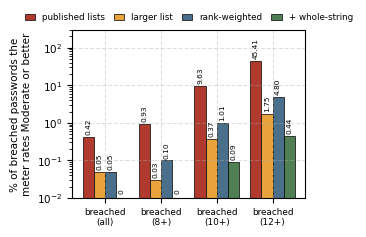

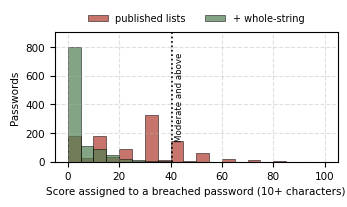


  on 'policy-compliant mutations', repair 2 and repair 3 assign identical scores: True
  (the whole-string rule costs nothing on this population, so figure 3
   plots three curves)


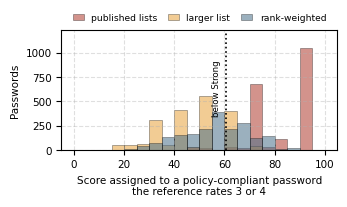

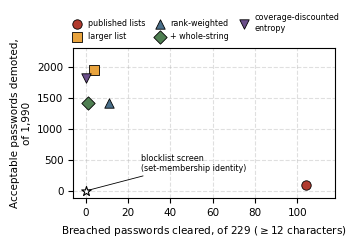

figures written: fig1_unsafe.png, fig2_distribution.png, fig3_cost.png, fig4_frontier.png


In [29]:
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 7.5, 'axes.grid': True,
                     'grid.linestyle': '--', 'grid.alpha': 0.4})

BKEYS = ['breached (all lengths)', 'breached (8+ chars)',
         'breached (10+ chars)', 'breached (12+ chars)']
BLABS = ['breached\n(all)', 'breached\n(8+)', 'breached\n(10+)', 'breached\n(12+)']
NAMES = [('published', 'published lists', '#b03a2e'),
         ('larger', 'larger list', '#e8a33d'),
         ('weighted', 'rank-weighted', '#4a6f8a'),
         ('wholestr', '+ whole-string', '#4f7f52')]

# Figure 1: unsafe rate by population on a log axis, all four configurations.
# The two non-breached populations are 0.00 under every configuration and are
# omitted; they are reported in the tables.
fig, ax = plt.subplots(figsize=(3.5, 2.4))
x = np.arange(len(BKEYS)); w = 0.2
for i, (key, lab, col) in enumerate(NAMES):
    vals = [REPAIRED.loc[k, 'pct_' + key] for k in BKEYS]
    off = (i - 1.5) * w
    ax.bar(x + off, [v if v > 0 else np.nan for v in vals], w, label=lab,
           color=col, edgecolor='black', linewidth=0.5)
    for xi, v in zip(x + off, vals):
        ax.text(xi, (v * 1.15) if v > 0 else 0.013,
                ('%.2f' % v) if v > 0 else '0',
                ha='center', va='bottom', rotation=90, fontsize=5.4)
ax.set_yscale('log')
ax.set_ylim(0.01, 300)
ax.set_xticks(x); ax.set_xticklabels(BLABS, fontsize=6.4)
ax.set_ylabel('% of breached passwords the\nmeter rates Moderate or better')
ax.legend(fontsize=6.3, loc='lower center', bbox_to_anchor=(0.5, 1.0),
          ncol=4, frameon=False, columnspacing=1.0, handlelength=1.2)
plt.tight_layout(); plt.savefig('fig1_unsafe.png', dpi=200, bbox_inches='tight')
plt.show()

# Figure 2: score distribution on the breached 10+ population
fig, ax = plt.subplots(figsize=(3.5, 2.1))
bins = np.arange(0, 105, 5)
ax.hist(RES[KEY]['score'], bins=bins, alpha=0.7, label='published lists',
        color='#b03a2e', edgecolor='black', linewidth=0.5)
ax.hist(RES4[KEY]['score'], bins=bins, alpha=0.7, label='+ whole-string',
        color='#4f7f52', edgecolor='black', linewidth=0.5)
ax.axvline(MOD_FLOOR - 0.5, color='black', ls=':', lw=1.2)
ax.set_ylim(0, ax.get_ylim()[1] * 1.08)
ax.text(MOD_FLOOR + 2.5, ax.get_ylim()[1] * 0.50, 'Moderate and above',
        fontsize=6.2, rotation=90, va='center', ha='center')
ax.set_xlabel('Score assigned to a breached password (10+ characters)')
ax.set_ylabel('Passwords')
ax.legend(fontsize=7, loc='lower center', bbox_to_anchor=(0.5, 1.0),
          ncol=2, frameon=False)
plt.tight_layout(); plt.savefig('fig2_distribution.png', dpi=200, bbox_inches='tight')
plt.show()

# Figure 3: the cost side. Repairs 2 and 3 differ only on passwords whose
# whole string is a list entry, which no policy-compliant mutation is, so
# we check that they coincide here and plot three curves rather than four.
K2 = 'policy-compliant mutations'
SAME_23 = bool((RES3[K2]['score'].values == RES4[K2]['score'].values).all())
print("\n  on '%s', repair 2 and repair 3 assign identical scores: %s"
      % (K2, SAME_23))
print("  (the whole-string rule costs nothing on this population, so"
      " figure 3\n   plots three curves)")

fig, ax = plt.subplots(figsize=(3.5, 2.1))
for key, lab, col in NAMES[:3]:
    R = dict(CONFIGS)[key]
    ax.hist(R[K2]['score'], bins=bins, alpha=0.55, label=lab,
            color=col, edgecolor='black', linewidth=0.4)
ax.axvline(STRONG_FLOOR - 0.5, color='black', ls=':', lw=1.2)
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
ax.text(STRONG_FLOOR - 4.0, ax.get_ylim()[1] * 0.52, 'below Strong',
        fontsize=6.2, rotation=90, va='center', ha='center')
ax.set_xlabel('Score assigned to a policy-compliant password\nthe reference rates 3 or 4')
ax.set_ylabel('Passwords')
ax.legend(fontsize=6.6, loc='lower center', bbox_to_anchor=(0.5, 1.0),
          ncol=3, frameon=False, columnspacing=1.2, handlelength=1.2)
plt.tight_layout(); plt.savefig('fig3_cost.png', dpi=200, bbox_inches='tight')
plt.show()

# Figure 4: the trade-off frontier -- every configuration on both axes
fig, ax = plt.subplots(figsize=(3.5, 2.5))
FNAMES = [('published', 'published lists', '#b03a2e', 'o'),
          ('larger', 'larger list', '#e8a33d', 's'),
          ('weighted', 'rank-weighted', '#4a6f8a', '^'),
          ('wholestr', '+ whole-string', '#4f7f52', 'D'),
          ('covent', 'coverage-discounted\nentropy', '#6b4f8a', 'v')]
for key, lab, col, mk in FNAMES:
    x = FRONTIER.loc[key, 'cl_12+']
    y = FRONTIER.loc[key, 'demoted_mut']
    ax.scatter([x], [y], s=46, color=col, marker=mk, edgecolor='black',
               linewidth=0.6, label=lab, zorder=3)
ax.scatter([0], [0], s=52, color='white', marker='*', edgecolor='black',
           linewidth=0.8, zorder=3)
ax.annotate('blocklist screen\n(set-membership identity)', xy=(0, 0),
            xytext=(26, 330), fontsize=5.8, ha='left',
            arrowprops=dict(arrowstyle='-', lw=0.6))
ax.set_xlabel('Breached passwords cleared, of 229 ($\\geq$12 characters)')
ax.set_ylabel('Acceptable passwords demoted,\nof 1,990')
ax.set_xlim(-6, 118)
ax.set_ylim(-110, 2300)
ax.legend(fontsize=5.8, loc='lower center', bbox_to_anchor=(0.5, 1.0),
          ncol=3, frameon=False, columnspacing=0.8, handletextpad=0.3)
plt.tight_layout(); plt.savefig('fig4_frontier.png', dpi=200, bbox_inches='tight')
plt.show()
print("figures written: fig1_unsafe.png, fig2_distribution.png,"
      " fig3_cost.png, fig4_frontier.png")


## T. environment

In [30]:
import scipy, zxcvbn as _zx
print()
print("python      ", sys.version.split()[0])
for m in [np, pd, scipy, matplotlib]:
    print("%-14s %s" % (m.__name__, m.__version__))
print("%-14s %s" % ("zxcvbn", getattr(_zx, '__version__', 'bundled')))
print("platform    ", platform.platform())
print("seed        ", SEED)



python       3.13.16
numpy          2.1.3
pandas         2.2.3
scipy          1.16.3
matplotlib     3.10.0
zxcvbn         bundled
platform     Linux-6.6.122+-x86_64-with-glibc2.39
seed         42
